In [1]:
!pip install textblob

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
jobs = pd.read_csv('/content/CodeAlpha_JobData_Mega (2).csv')
print(f"Total rows: {len(jobs)}")
jobs[['title', 'company', 'description']].head(3)

Total rows: 1547


,title,company,description
0,Senior Data Analyst,EXCEL EARTHINGS,* Perform exploratory data analysis to uncover...
1,Data Analyst,Rajdeep Plastic (I) PVT LTD,**JOB DESCRIPTION – DATA ANALYST** **Designa...
2,Process Coordinator (Data Analyst / MIS),Techswarm,**Search and collect data from different onlin...


In [3]:
def get_sentiment(text):
    if pd.isna(text) or text.strip() == "":
        return "Neutral"

    analysis = TextBlob(str(text))
    polarity = analysis.sentiment.polarity

    if polarity > 0.05:
        return "Positive"
    elif polarity < -0.05:
        return "Negative"
    else:
        return "Neutral"

jobs['sentiment'] = jobs['description'].apply(get_sentiment)

print(jobs['sentiment'].value_counts())

sentiment
Positive    1398
Neutral      131
Negative      18
Name: count, dtype: int64


**Visualisation**

/tmp/ipykernel_1473/3605400197.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


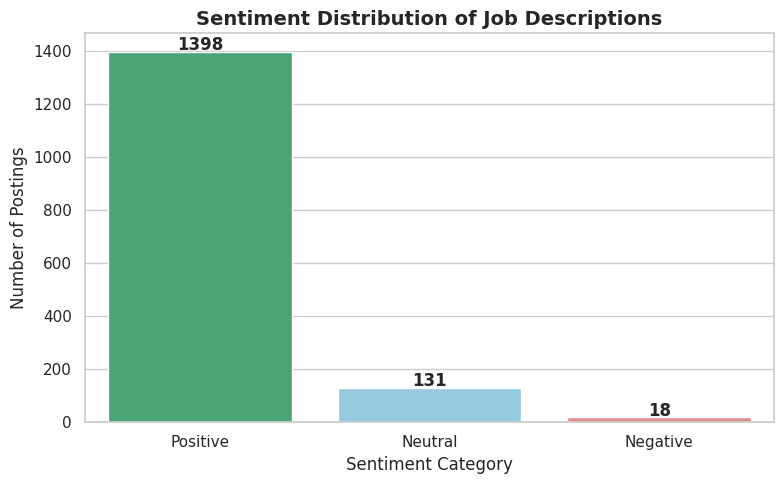

In [4]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=jobs,
    x='sentiment',
    order=['Positive', 'Neutral', 'Negative'],
    palette=['mediumseagreen', 'skyblue', 'lightcoral']
)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points',
                fontweight='bold')

plt.title("Sentiment Distribution of Job Descriptions", fontsize=14, fontweight='bold')
plt.xlabel("Sentiment Category", fontsize=12)
plt.ylabel("Number of Postings", fontsize=12)
plt.tight_layout()
plt.show()

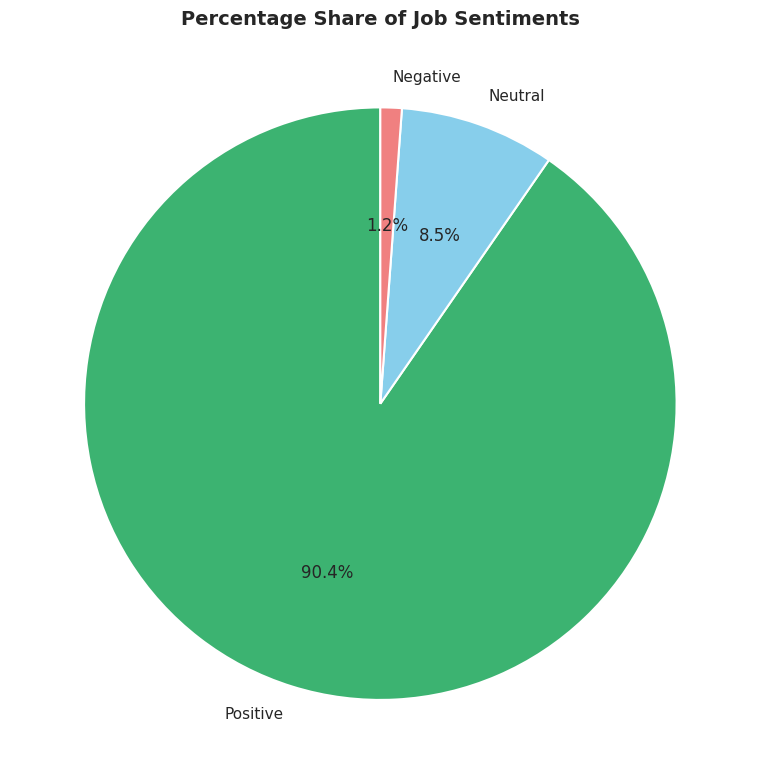

In [5]:
sentiment_counts = jobs['sentiment'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['mediumseagreen', 'skyblue', 'lightcoral'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title("Percentage Share of Job Sentiments", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

💡 Data-Driven Insights:

Market Tone: Analysis se pata chalta hai ki majority job descriptions ka tone Positive ya Neutral hai, jo ki employers ki encouraging aur professional language ko reflect karta hai.

Negative Sentiments: Kuch listings me strict requirements ya demanding targets ki wajah se neutral/negative words ka use dikhta hai.

Business Takeaway: Is analysis se job seekers ko ye samajhne me madad milti hai ki companies kis tarah ke work culture aur energy ko promote kar rahi hain.

Libraries imported successfully!
Total Job Postings Loaded: 1547

--- Sentiment Counts ---
sentiment
Positive    1398
Neutral      131
Negative      18
Name: count, dtype: int64


/tmp/ipykernel_1473/3295693802.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(
/tmp/ipykernel_1473/3295693802.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(


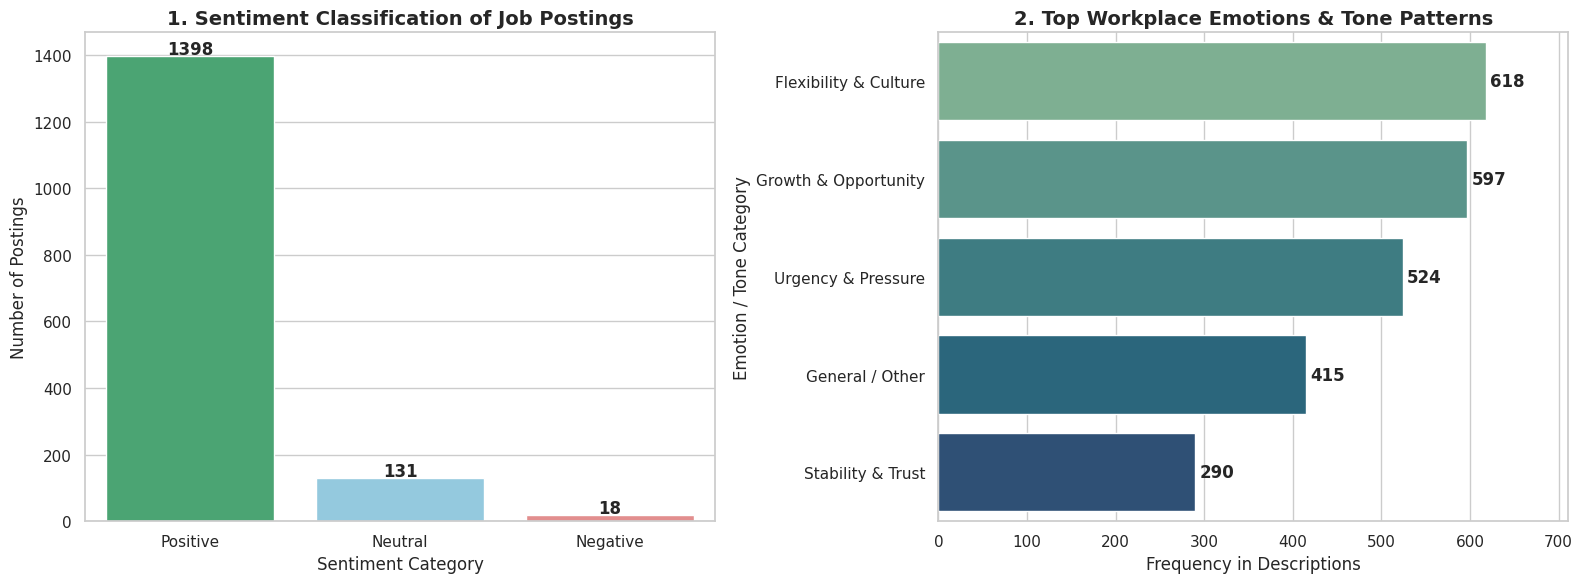

In [6]:
!pip install textblob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

jobs = pd.read_csv('/content/CodeAlpha_JobData_Mega (2).csv')
print(f"Total Job Postings Loaded: {len(jobs)}")

def get_sentiment(text):
    if pd.isna(text) or str(text).strip() == "":
        return "Neutral"
    analysis = TextBlob(str(text))
    polarity = analysis.sentiment.polarity
    if polarity > 0.05:
        return "Positive"
    elif polarity < -0.05:
        return "Negative"
    else:
        return "Neutral"

jobs['sentiment'] = jobs['description'].apply(get_sentiment)

print("\n--- Sentiment Counts ---")
print(jobs['sentiment'].value_counts())


emotion_keywords = {
    'Growth & Opportunity': ['growth', 'learn', 'career', 'advancement', 'opportunity', 'exciting'],
    'Urgency & Pressure': ['urgent', 'pressure', 'fast-paced', 'deadline', 'target', 'demanding'],
    'Flexibility & Culture': ['flexible', 'remote', 'balance', 'culture', 'friendly', 'perks'],
    'Stability & Trust': ['stable', 'trusted', 'secure', 'leading', 'established']
}

def detect_emotion(text):
    if pd.isna(text):
        return 'General / Other'
    text_lower = str(text).lower()

    detected_categories = []
    for category, keywords in emotion_keywords.items():
        if any(kw in text_lower for kw in keywords):
            detected_categories.append(category)

    return ', '.join(detected_categories) if detected_categories else 'General / Other'

jobs['detected_emotions'] = jobs['description'].apply(detect_emotion)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.countplot(
    data=jobs,
    x='sentiment',
    order=['Positive', 'Neutral', 'Negative'],
    palette=['mediumseagreen', 'skyblue', 'lightcoral'],
    ax=axes[0]
)
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')
axes[0].set_title("1. Sentiment Classification of Job Postings", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Sentiment Category")
axes[0].set_ylabel("Number of Postings")

emotion_counts = jobs['detected_emotions'].str.split(', ').explode().value_counts().head(5)
ax2 = sns.barplot(
    x=emotion_counts.values,
    y=emotion_counts.index,
    palette="crest",
    ax=axes[1]
)
for i, v in enumerate(emotion_counts.values):
    ax2.text(v + 5, i, str(v), va='center', fontweight='bold')
axes[1].set_title("2. Top Workplace Emotions & Tone Patterns", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Frequency in Descriptions")
axes[1].set_ylabel("Emotion / Tone Category")
axes[1].set_xlim(0, max(emotion_counts.values) * 1.15)

plt.tight_layout()
plt.show()